# 23CSE301 Machine Learning Capstone — Clustering Track

**Dataset:** Gas Turbine CO and NOx Emission (2011–2015 combined)

**Objective:** Group turbine operating observations using the nine operating-condition features, then interpret CO and NOx emissions by cluster. Emissions and Year are not used as clustering inputs.

**Required algorithms:** K-Means and Agglomerative Hierarchical Clustering.

**Evaluation:** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, elbow curve, linkage comparison, dendrogram, PCA visualisations and t-SNE.

**Reproducibility:** Random seed = 42. K-Means is fitted on all cleaned observations. Agglomerative linkage comparisons and the dendrogram use the same reproducible sample of up to 5,000 rows to control memory use.

## 1. Import libraries and set reproducibility

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (8, 5)
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the combined dataset

Place `gas_turbine_combined.csv` or `gas_turbine_combined_full_column_names.csv` in the same folder as this notebook. The code accepts either the abbreviated or descriptive column names.

In [2]:
DATA_CANDIDATES = ["gas_turbine_combined_full_column_names.csv", "gas_turbine_combined.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Place gas_turbine_combined_full_column_names.csv or gas_turbine_combined.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

# Standardise column names internally so either supplied CSV works.
LONG_TO_SHORT = {
    "Ambient_Temperature": "AT", "Ambient_Pressure": "AP", "Ambient_Humidity": "AH",
    "Air_Filter_Differential_Pressure": "AFDP", "Gas_Turbine_Exhaust_Pressure": "GTEP",
    "Turbine_Inlet_Temperature": "TIT", "Turbine_After_Temperature": "TAT",
    "Turbine_Energy_Yield": "TEY", "Compressor_Discharge_Pressure": "CDP",
    "Carbon_Monoxide_Emission": "CO", "Nitrogen_Oxides_Emission": "NOX",
}
df = df.rename(columns=LONG_TO_SHORT)

print("Loaded file:", DATA_PATH)
print("Raw dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Loaded file: gas_turbine_combined_full_column_names.csv
Raw dataset shape: (36733, 12)
Columns: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX', 'Year']


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


## 3. Dataset audit

Inspect data types, missing values, duplicate rows and summary statistics before preprocessing.

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("Exact duplicate rows:", df.duplicated().sum())

print("Summary statistics:")
display(df.describe().T.round(3))

Data types:


,dtype
AT,float64
AP,float64
AH,float64
AFDP,float64
GTEP,float64
TIT,float64
TAT,float64
TEY,float64
CDP,float64
CO,float64


Missing values by column:


,missing_values
AT,0
AP,0
AH,0
AFDP,0
GTEP,0
TIT,0
TAT,0
TEY,0
CDP,0
CO,0


Exact duplicate rows: 7
Summary statistics:


,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.713,7.447,-6.235,11.781,17.801,23.665,37.103
AP,36733.0,1013.070,6.463,985.850,1008.800,1012.600,1017.000,1036.600
AH,36733.0,77.867,14.461,24.085,68.188,80.470,89.376,100.200
AFDP,36733.0,3.926,0.774,2.087,3.356,3.938,4.377,7.611
GTEP,36733.0,25.564,4.196,17.698,23.129,25.104,29.061,40.716
TIT,36733.0,1081.428,17.536,1000.800,1071.800,1085.900,1097.000,1100.900
TAT,36733.0,546.159,6.842,511.040,544.720,549.880,550.040,550.610
TEY,36733.0,133.506,15.619,100.020,124.450,133.730,144.080,179.500
CDP,36733.0,12.061,1.089,9.852,11.435,11.965,12.855,15.159
CO,36733.0,2.372,2.263,0.000,1.182,1.714,2.843,44.103


### Data cleaning

Remove exact duplicate records. Missing/non-finite values in the operating features are handled before clustering. Keep `Year` and emission columns for later interpretation, but do not use them as clustering inputs.

In [4]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before removing exact duplicates:", rows_before)
print("Rows after removing exact duplicates:", len(df))
print("Exact duplicates removed:", rows_before - len(df))

# Replace infinite values with NaN, then remove rows missing required numeric inputs.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
required_for_analysis = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP", "CO", "NOX"]
missing_required = [c for c in required_for_analysis if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")
rows_before_missing = len(df)
df = df.dropna(subset=required_for_analysis).reset_index(drop=True)
print("Rows removed due to missing/non-finite required values:", rows_before_missing - len(df))
print("Cleaned dataset shape:", df.shape)
print("Missing values remaining in required columns:", int(df[required_for_analysis].isna().sum().sum()))

Rows before removing exact duplicates: 36733
Rows after removing exact duplicates: 36726
Exact duplicates removed: 7
Rows removed due to missing/non-finite required values: 0
Cleaned dataset shape: (36726, 12)
Missing values remaining in required columns: 0


## 4. Select features for clustering

Use all nine turbine operating-condition features. Keep CO and NOx out of model fitting so they can be compared across the resulting clusters afterward.

In [5]:
operating_features = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
emission_features = ["CO", "NOX"]

missing_columns = [c for c in operating_features + emission_features if c not in df.columns]
if missing_columns:
    raise ValueError(f"Expected columns not found: {missing_columns}")

X = df[operating_features].astype(float).copy()
print("Number of clustering features:", X.shape[1])
print("Features used:", operating_features)
print("Rows used for K-Means:", len(X))
display(X.head())

Number of clustering features: 9
Features used: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
Rows used for K-Means: 36726


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910


### Quick exploratory visualisations
Inspect operating and emission distributions, potential outliers and CO–NOX relationships before clustering. Emissions remain excluded from clustering inputs.


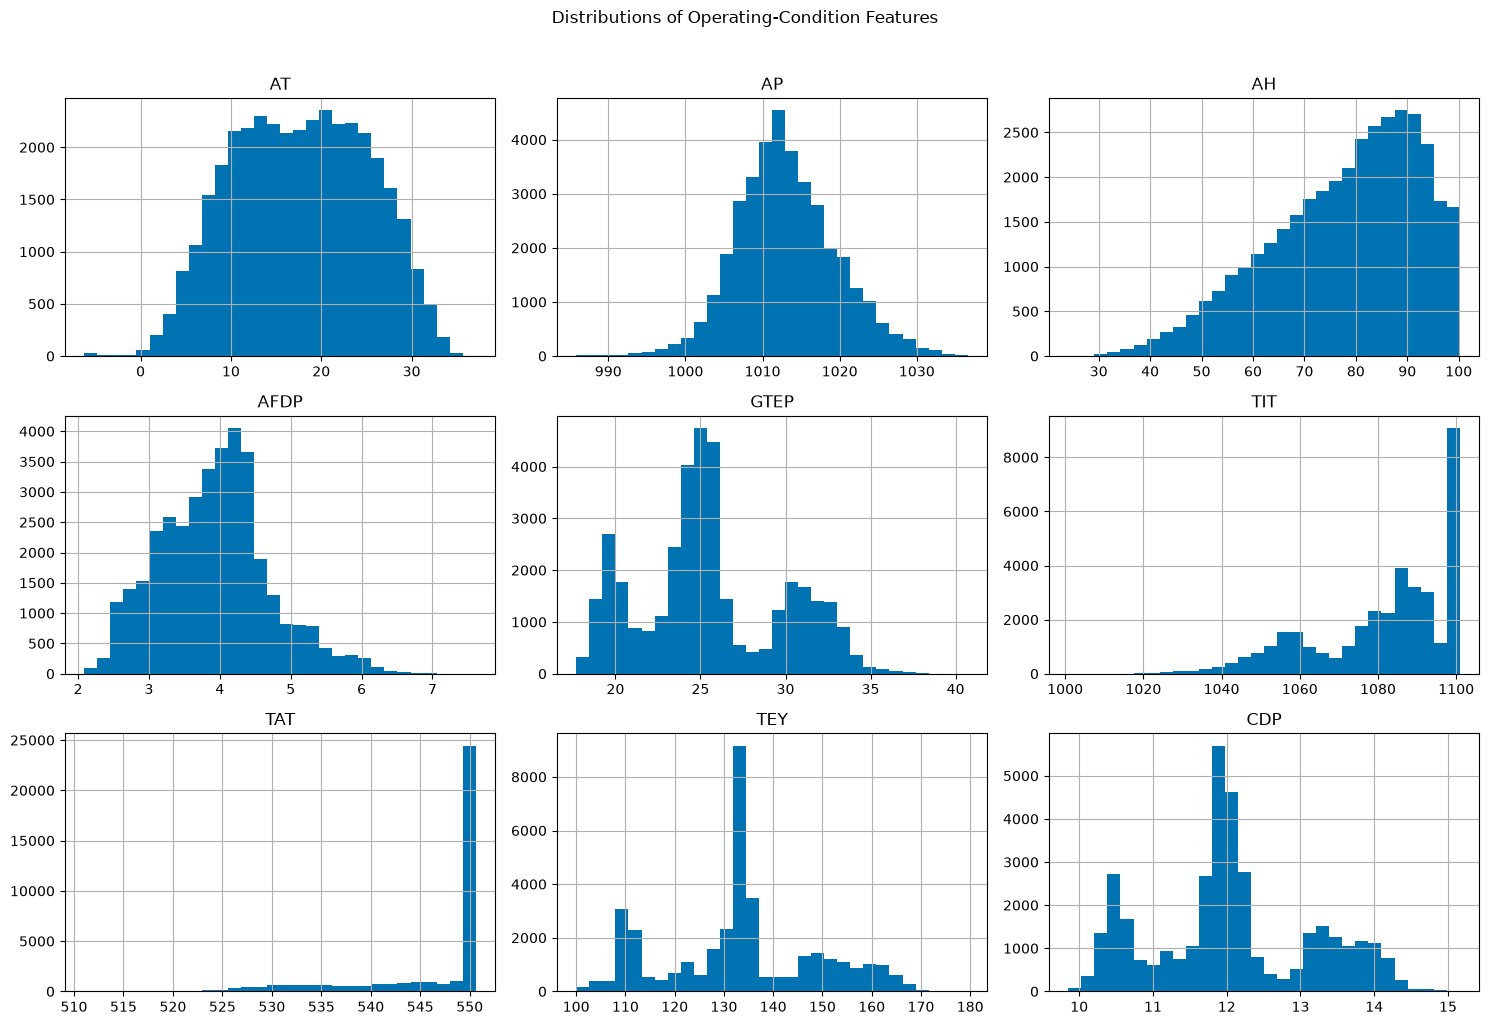

In [6]:
X.hist(figsize=(15, 10), bins=30)
plt.suptitle("Distributions of Operating-Condition Features", y=1.02)
plt.tight_layout()
plt.show()

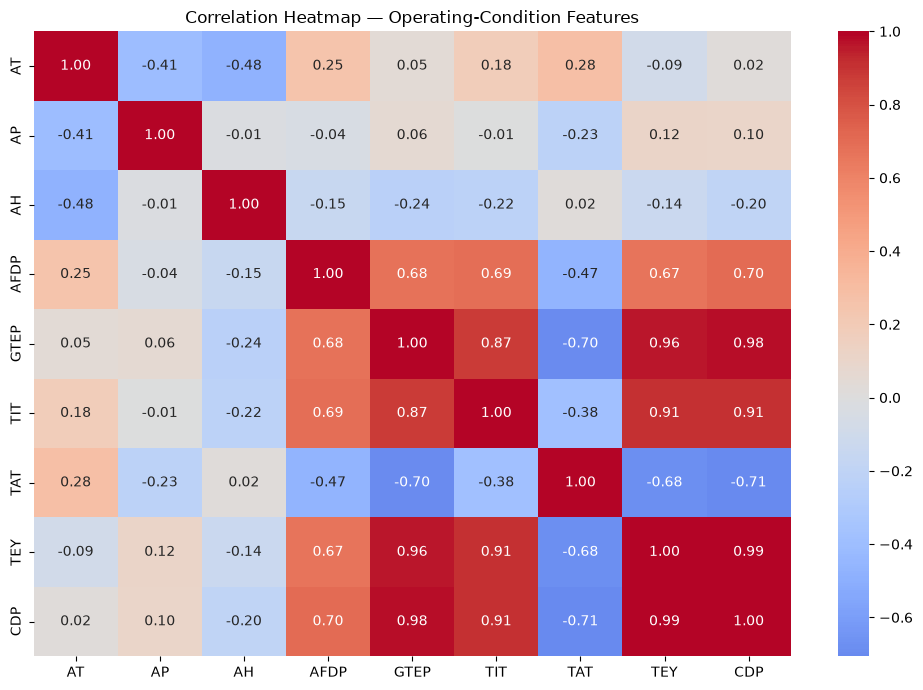

In [7]:
plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap — Operating-Condition Features")
plt.tight_layout()
plt.show()

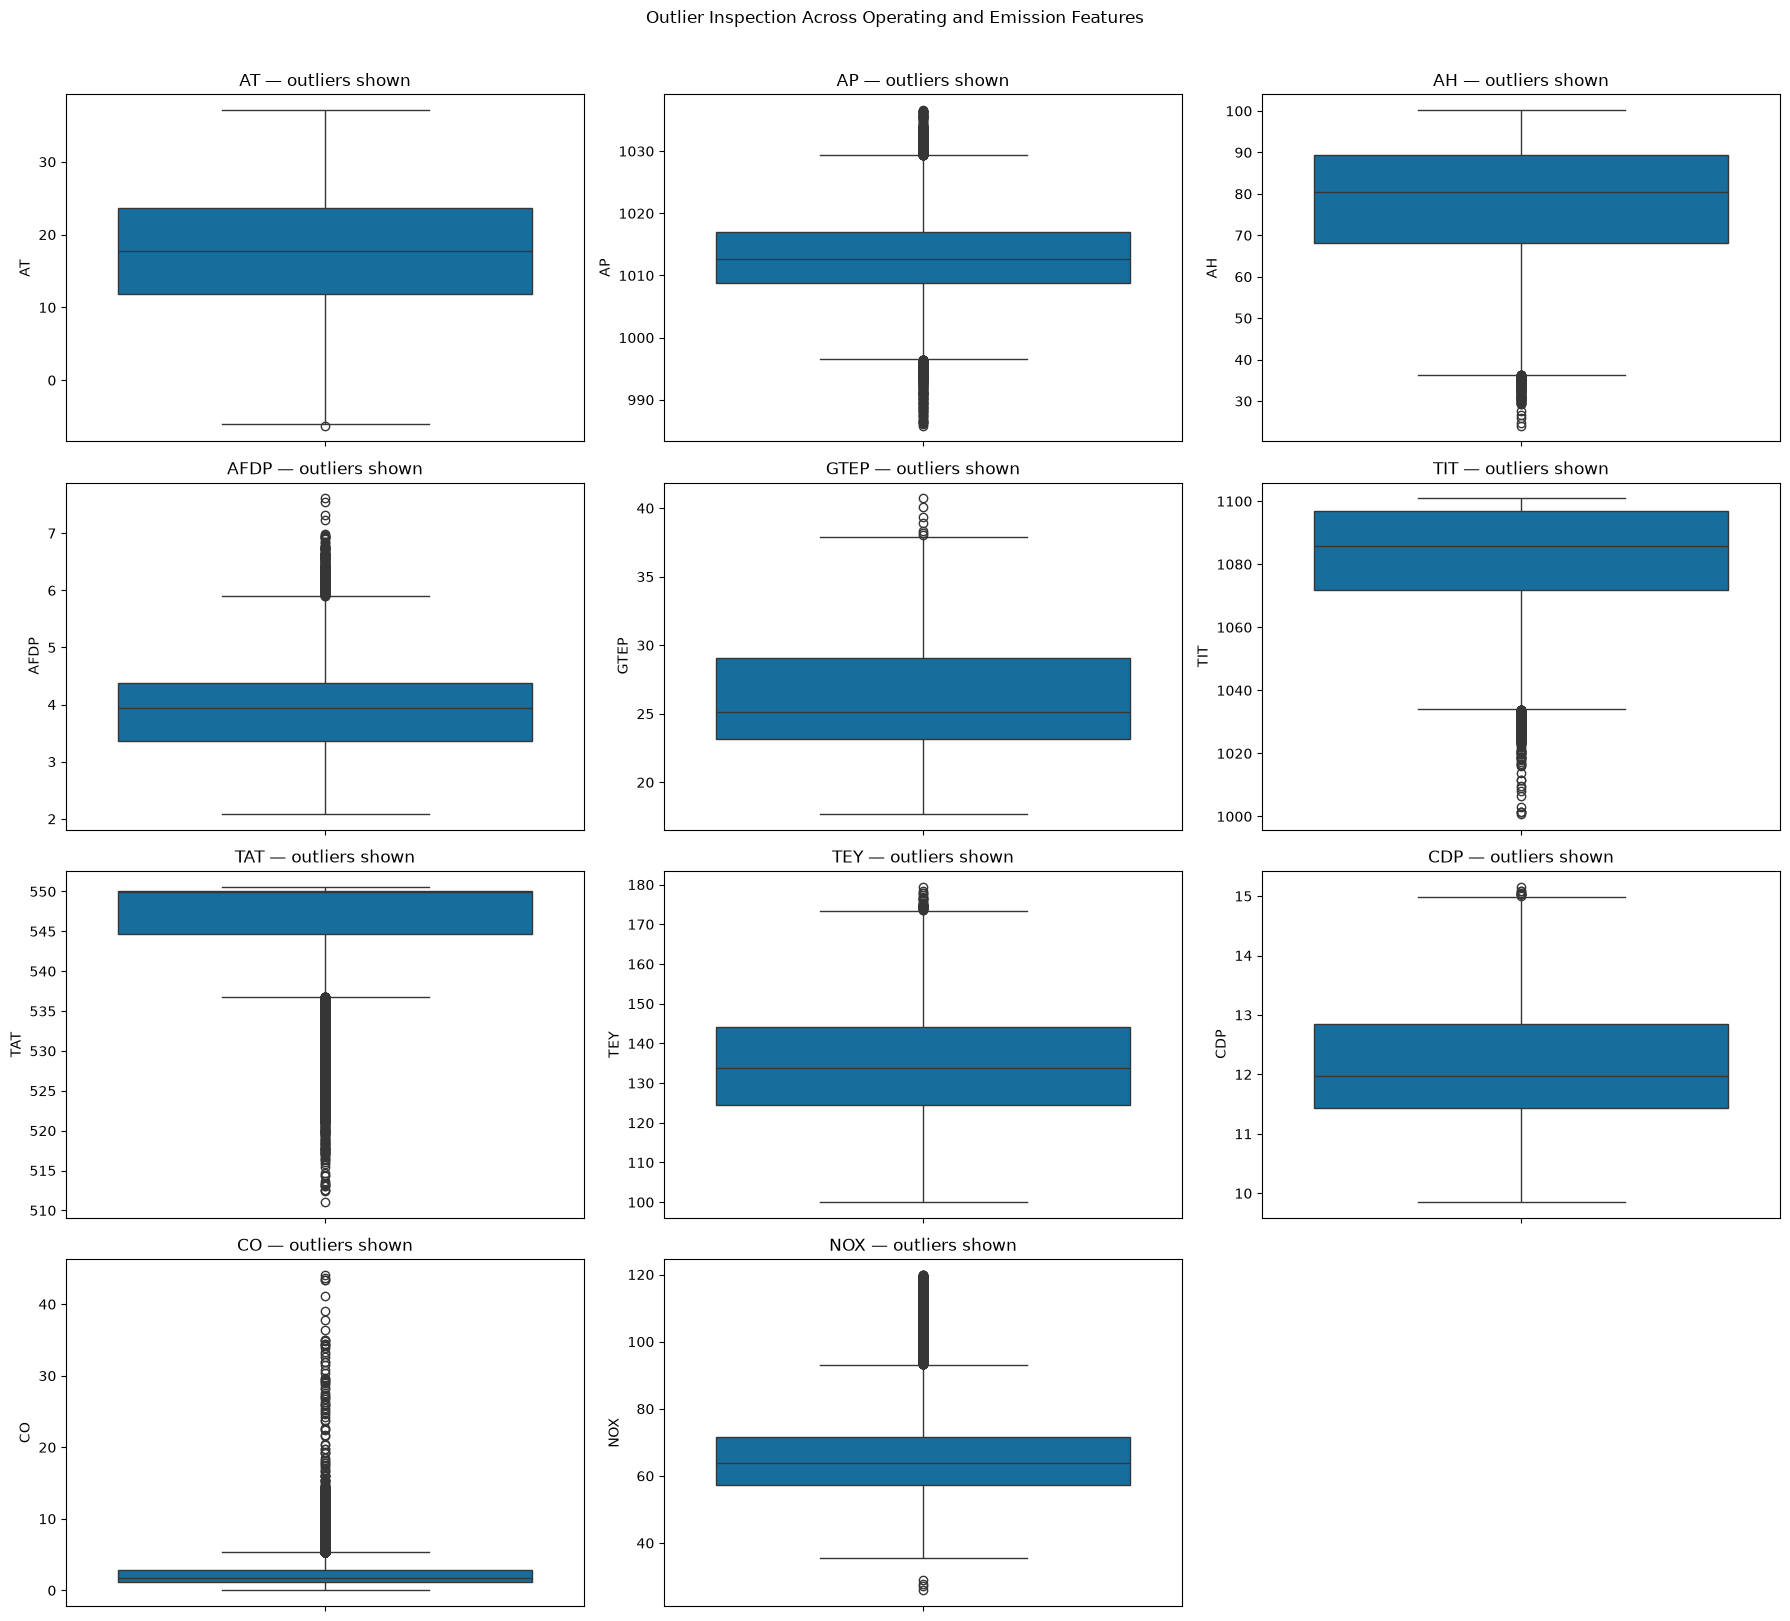

In [8]:
# Show outliers for every operating and emission feature in one multi-panel figure.
boxplot_features = operating_features + emission_features
columns = 3
rows = int(np.ceil(len(boxplot_features) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(18, 4 * rows))
axes = np.asarray(axes).reshape(-1)

for ax, feature in zip(axes, boxplot_features):
    sns.boxplot(y=df[feature], showfliers=True, ax=ax)
    ax.set_title(f"{feature} — outliers shown")
    ax.set_xlabel("")
    ax.set_ylabel(feature)

for ax in axes[len(boxplot_features):]:
    ax.set_visible(False)

fig.suptitle("Outlier Inspection Across Operating and Emission Features", y=1.01)
plt.tight_layout()
plt.show()

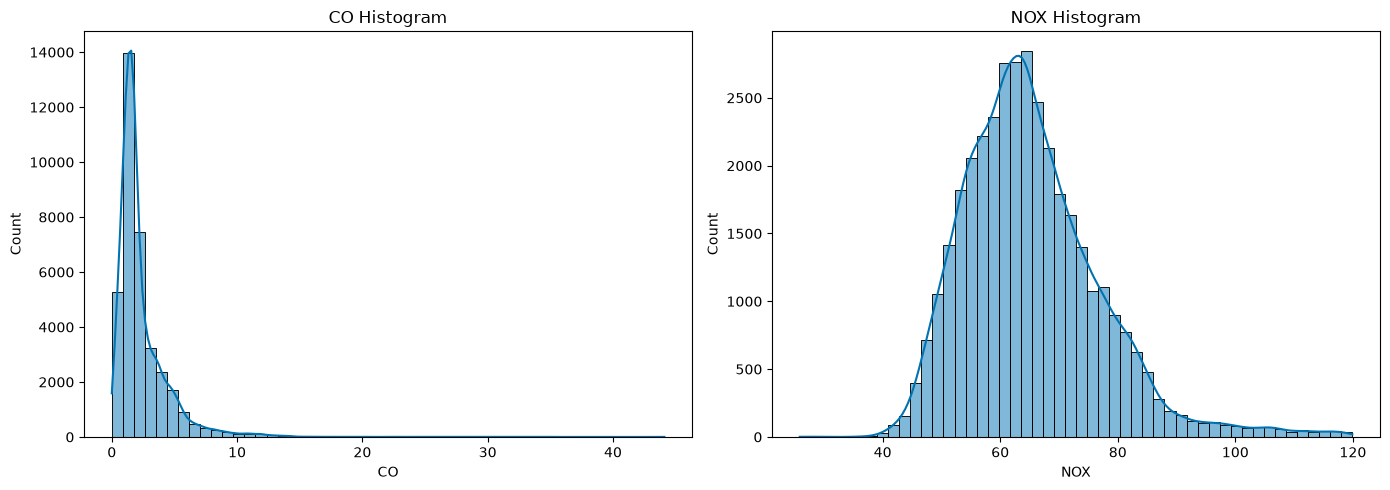

In [9]:
# Compare both emission distributions side by side in one cell.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="CO", bins=50, kde=True, ax=axes[0])
axes[0].set_title("CO Histogram")
axes[0].set_xlabel("CO")
sns.histplot(data=df, x="NOX", bins=50, kde=True, ax=axes[1])
axes[1].set_title("NOX Histogram")
axes[1].set_xlabel("NOX")
plt.tight_layout()
plt.show()

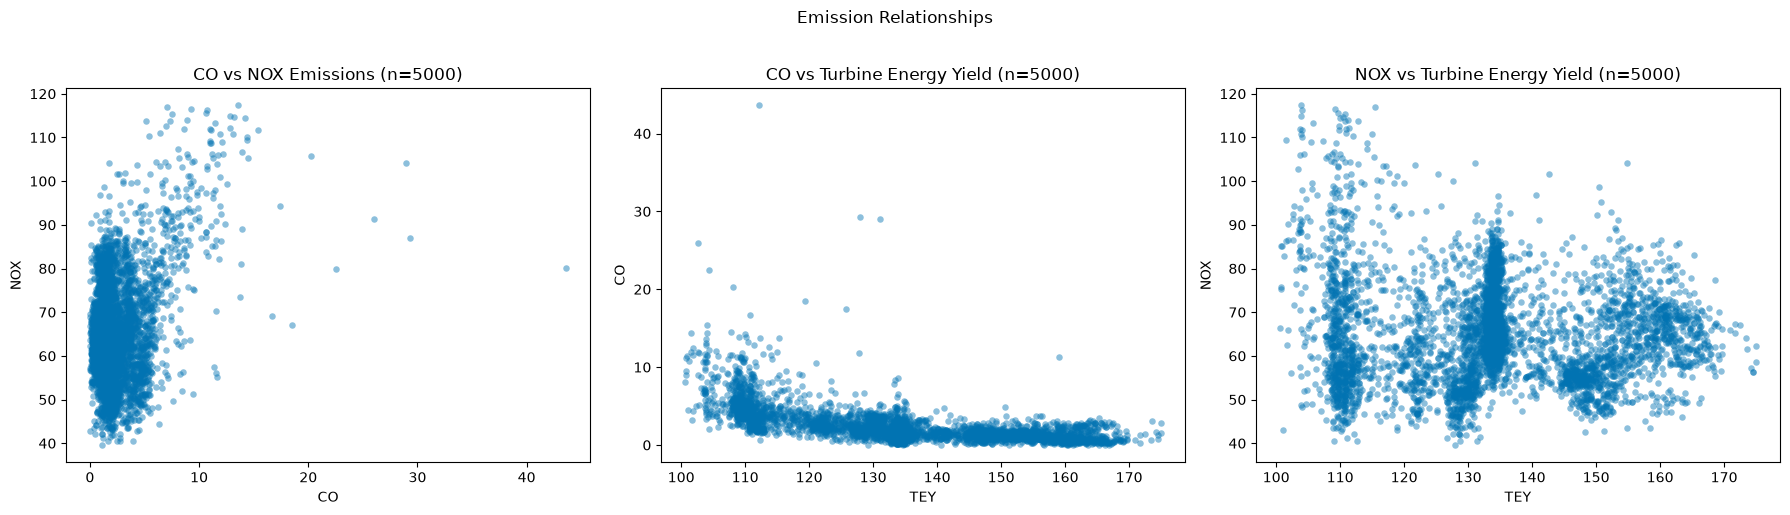

In [10]:
# Use the same reproducible subset for all three emission scatterplots.
SCATTER_SAMPLE_SIZE = min(5_000, len(df))
scatter_positions = np.sort(
    np.random.RandomState(RANDOM_STATE).choice(
        len(df), size=SCATTER_SAMPLE_SIZE, replace=False
    )
)
scatter_sample = df.iloc[scatter_positions]

scatter_pairs = [
    ("CO", "NOX", "CO vs NOX Emissions"),
    ("TEY", "CO", "CO vs Turbine Energy Yield"),
    ("TEY", "NOX", "NOX vs Turbine Energy Yield"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x_col, y_col, title) in zip(axes, scatter_pairs):
    sns.scatterplot(
        data=scatter_sample, x=x_col, y=y_col,
        alpha=0.45, s=22, linewidth=0, ax=ax
    )
    ax.set_title(f"{title} (n={SCATTER_SAMPLE_SIZE})")

fig.suptitle("Emission Relationships", y=1.02)
plt.tight_layout()
plt.show()


### Outlier handling for clustering input features

The box plots show potential outliers, but these may be genuine gas-turbine operating conditions. To reduce the influence of extreme values without deleting observations, this step applies **IQR capping** to the nine operating features used for clustering. Values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` are capped at those limits. CO and NOX are not changed because they are reserved for post-clustering interpretation. The original row count is preserved.

In [11]:
# Apply IQR capping only to the operating features used as clustering inputs.
# This reduces extreme-value influence without deleting rows.
outlier_limits = {}
outlier_summary = []

for feature in operating_features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    below = int((df[feature] < lower_limit).sum())
    above = int((df[feature] > upper_limit).sum())
    outlier_limits[feature] = (lower_limit, upper_limit)
    df[feature] = df[feature].clip(lower=lower_limit, upper=upper_limit)
    outlier_summary.append({
        "Feature": feature,
        "Lower limit": lower_limit,
        "Upper limit": upper_limit,
        "Values capped below": below,
        "Values capped above": above,
    })

# Refresh X so scaling and clustering use the capped operating-feature values.
X = df[operating_features].copy()

print("Outlier handling: IQR capping")
print("Rows retained:", len(df))
display(pd.DataFrame(outlier_summary).round(4))

Outlier handling: IQR capping
Rows retained: 36726


,Feature,Lower limit,Upper limit,Values capped below,Values capped above
0,AT,-6.0479,41.4911,1,0
1,AP,996.5000,1029.3000,237,375
2,AH,36.3956,121.1606,130,0
3,AFDP,1.8236,5.9087,0,557
4,GTEP,14.2296,37.9566,0,7
5,TIT,1034.0000,1134.8000,315,0
6,TAT,536.7400,558.0200,4955,0
7,TEY,95.0050,173.5250,0,33
8,CDP,9.3044,14.9834,0,10


## 5. Scale the numerical features

K-Means and hierarchical clustering are distance-based, so feature scaling is necessary. Use `StandardScaler` as the main baseline. The notebook retains only one full scaled matrix to reduce memory usage.

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)
print("Data type:", X_scaled.dtype)
print("Approximate feature means:", np.round(X_scaled.mean(axis=0), 3))
print("Approximate feature standard deviations:", np.round(X_scaled.std(axis=0), 3))

Scaled matrix shape: (36726, 9)
Data type: float64
Approximate feature means: [-0. -0.  0. -0.  0.  0. -0. -0. -0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. K-Means — Elbow curve

Fit K-Means for a range of `k` values on the full cleaned dataset. Inertia decreases as `k` increases; use the elbow as one piece of evidence rather than an automatic decision rule.

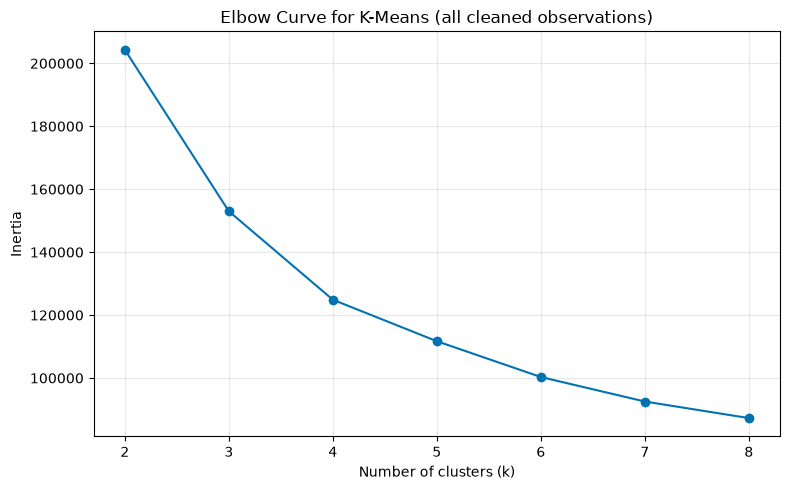

In [13]:
k_values = range(2, 9)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Curve for K-Means (all cleaned observations)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### K-Means — compare candidate values of k

For each candidate, fit K-Means on all cleaned rows and compute Silhouette, Davies–Bouldin and Calinski–Harabasz on all rows. Full-data Silhouette is more computationally intensive, but every candidate is evaluated consistently. Consider all metrics, the elbow curve, cluster sizes and interpretability when choosing `k`.


In [14]:
# Fit and evaluate every candidate k on all cleaned observations.
k_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    sizes = np.bincount(labels, minlength=k)
    k_rows.append({
        "k": k,
        "Inertia (all rows)": model.inertia_,
        "Silhouette (all rows)": silhouette_score(X_scaled, labels),
        "Davies-Bouldin (all rows)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (all rows)": calinski_harabasz_score(X_scaled, labels),
        "Smallest cluster (all rows)": int(sizes.min()),
        "Largest cluster (all rows)": int(sizes.max()),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

sil_col = "Silhouette (all rows)"

,k,Inertia (all rows),Silhouette (all rows),Davies-Bouldin (all rows),Calinski-Harabasz (all rows),Smallest cluster (all rows),Largest cluster (all rows)
0,2,204310.7196,0.3810,1.0544,22688.1215,9605,27121
1,3,152996.1428,0.3184,1.2105,21306.8276,8691,18904
2,4,124884.1098,0.2913,1.1888,20157.0570,6833,12606
3,5,111696.3314,0.2662,1.2430,17986.1980,6505,8899
4,6,100319.6730,0.2577,1.2549,16853.0737,4273,7560
5,7,92531.5312,0.2515,1.3527,15740.9712,2705,7222
6,8,87266.7945,0.2389,1.4059,14622.3054,2702,7155


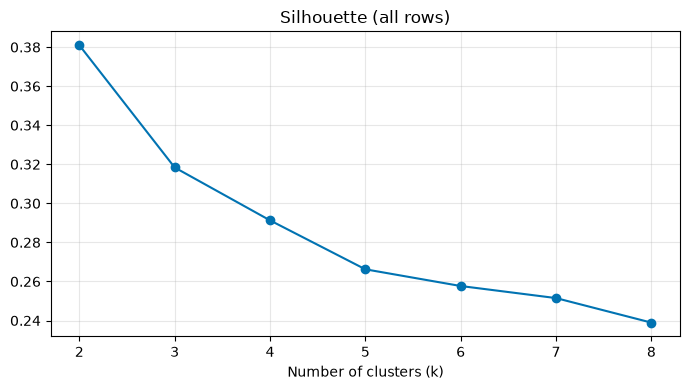

In [15]:
sil_col = "Silhouette (all rows)"
plt.figure(figsize=(7, 4))
plt.plot(k_table["k"], k_table[sil_col], marker="o")
plt.title(sil_col)
plt.xlabel("Number of clusters (k)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

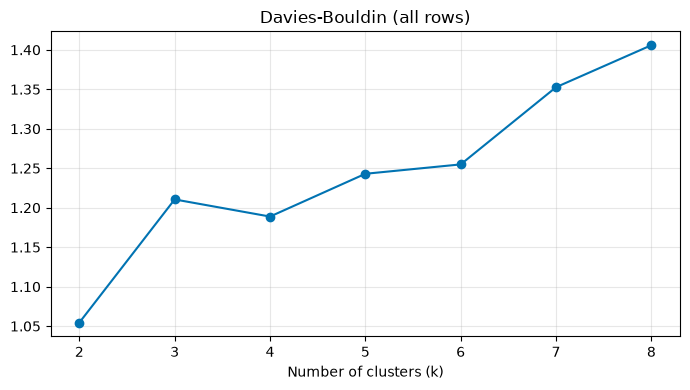

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(k_table["k"], k_table["Davies-Bouldin (all rows)"], marker="o")
plt.title("Davies-Bouldin (all rows)")
plt.xlabel("Number of clusters (k)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

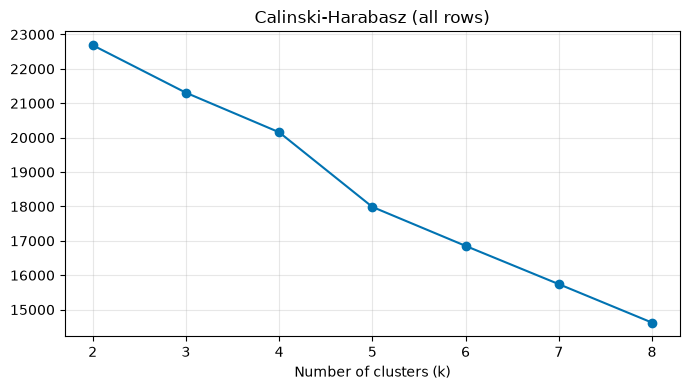

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(k_table["k"], k_table["Calinski-Harabasz (all rows)"], marker="o")
plt.title("Calinski-Harabasz (all rows)")
plt.xlabel("Number of clusters (k)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fit the selected K-Means model

Set `KMEANS_K` after reviewing the elbow curve and comparison table. The default is `3` as a transparent starting candidate, not a claim that it is universally optimal. The final K-Means model is fitted on every cleaned observation.

In [18]:
# Review the elbow curve, metric table, cluster sizes and interpretability before finalising k.
# Default candidate is 3; change this value only when your evidence supports another choice.
KMEANS_K = 3
print("K-Means cluster count selected for analysis:", KMEANS_K)

kmeans = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)  # all cleaned observations

df["KMeans_Cluster"] = kmeans_labels
print("K-Means cluster counts on the full cleaned dataset:")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("instances"))

K-Means cluster count selected for analysis: 3
K-Means cluster counts on the full cleaned dataset:


,instances
KMeans_Cluster,
0,18904
1,9131
2,8691


### K-Means cluster profile heatmap

Compare cluster mean profiles across the operating features and reserved CO/NOX interpretation columns. Values show each cluster mean’s distance from the overall mean in standard deviations.


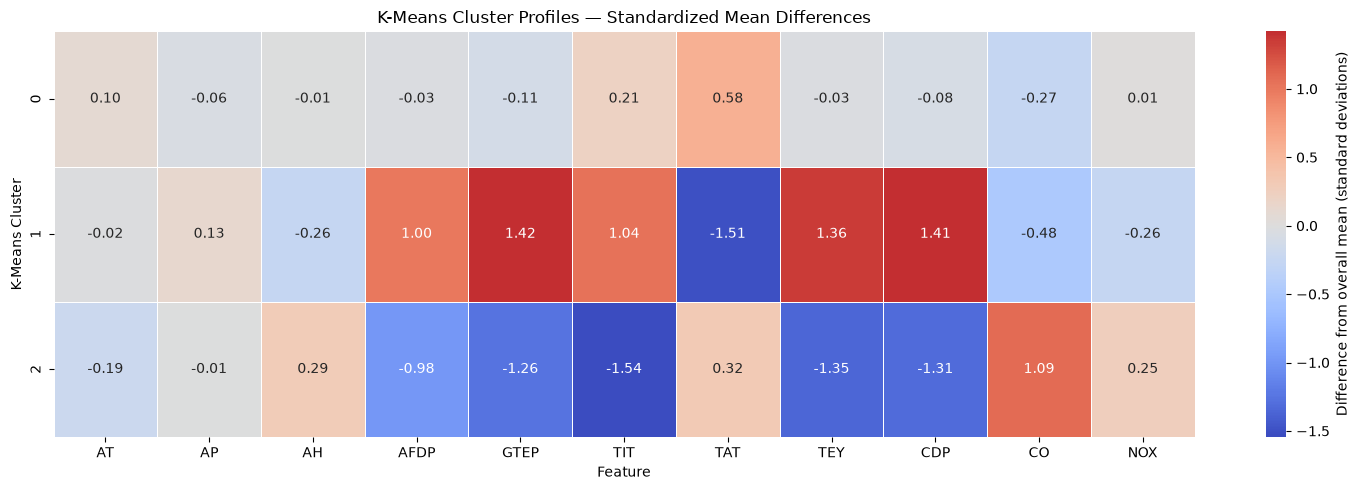

In [19]:
# Heatmap of cluster mean profiles, scaled by each feature's overall standard deviation.
profile_features = operating_features + emission_features
cluster_means = df.groupby("KMeans_Cluster")[profile_features].mean()
overall_means = df[profile_features].mean()
overall_stds = df[profile_features].std().replace(0, np.nan)
cluster_profile_z = (cluster_means - overall_means) / overall_stds

plt.figure(figsize=(15, 5))
sns.heatmap(cluster_profile_z, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            linewidths=0.5, cbar_kws={"label": "Difference from overall mean (standard deviations)"})
plt.title("K-Means Cluster Profiles — Standardized Mean Differences")
plt.xlabel("Feature")
plt.ylabel("K-Means Cluster")
plt.tight_layout()
plt.show()


## 7. Agglomerative Hierarchical Clustering — compare linkage strategies

Compare Ward, complete, average and single linkage on one reproducible sample of up to 5,000 cleaned observations to keep memory use manageable. The full cleaned dataset is used for K-Means.


In [20]:
# One reproducible sample is used for all hierarchical linkage and same-sample model comparisons.
HIERARCHICAL_SAMPLE_SIZE = min(5_000, len(df))
sample_positions = np.sort(
    np.random.RandomState(RANDOM_STATE).choice(
        len(df), size=HIERARCHICAL_SAMPLE_SIZE, replace=False
    )
)
sample_df = df.iloc[sample_positions].copy()
X_hier = X_scaled[sample_positions]

print("Rows used for hierarchical clustering:", len(X_hier))
print("Rows used to fit final K-Means:", len(df))


Rows used for hierarchical clustering: 5000
Rows used to fit final K-Means: 36726


In [21]:
linkage_results = []
hier_labels = {}

for linkage_name in ["ward", "complete", "average", "single"]:
    agg = AgglomerativeClustering(n_clusters=KMEANS_K, linkage=linkage_name)
    labels = agg.fit_predict(X_hier)
    hier_labels[linkage_name] = labels
    sizes = np.bincount(labels)
    linkage_results.append({
        "Linkage": linkage_name,
        "Smallest cluster": int(sizes.min()),
        "Largest cluster": int(sizes.max()),
        "Silhouette Score": silhouette_score(X_hier, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_hier, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_hier, labels)
    })

linkage_results_df = pd.DataFrame(linkage_results).sort_values(
    "Silhouette Score", ascending=False
).reset_index(drop=True)

# A linkage that leaves a tiny cluster (under 1% of the sample) is not a meaningful result
MIN_CLUSTER_SIZE = int(0.01 * len(X_hier))
linkage_results_df["Valid (no tiny cluster)"] = linkage_results_df["Smallest cluster"] >= MIN_CLUSTER_SIZE
display(linkage_results_df.round(4))

valid_links = linkage_results_df[linkage_results_df["Valid (no tiny cluster)"]]
AGG_LINKAGE = valid_links.iloc[0]["Linkage"] if len(valid_links) else "ward"
print(f"Selected linkage: {AGG_LINKAGE} (highest Silhouette among linkages with no tiny cluster; "
      f"minimum cluster size = {MIN_CLUSTER_SIZE} rows)")
rejected = linkage_results_df[~linkage_results_df["Valid (no tiny cluster)"]]["Linkage"].tolist()
if rejected:
    print("Rejected because of a tiny cluster (their metric values are not meaningful):", rejected)

,Linkage,Smallest cluster,Largest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Valid (no tiny cluster)
0,average,2,3678,0.3242,0.9286,1544.8512,False
1,complete,1023,2906,0.2890,1.1981,2462.2565,True
2,ward,947,2908,0.2878,1.1905,2454.8464,True
3,single,1,4998,0.0904,0.7218,2.7109,False


Selected linkage: complete (highest Silhouette among linkages with no tiny cluster; minimum cluster size = 50 rows)
Rejected because of a tiny cluster (their metric values are not meaningful): ['average', 'single']


### Dendrogram

The dendrogram uses up to 5,000 rows from the same reproducible sample used for linkage comparisons.


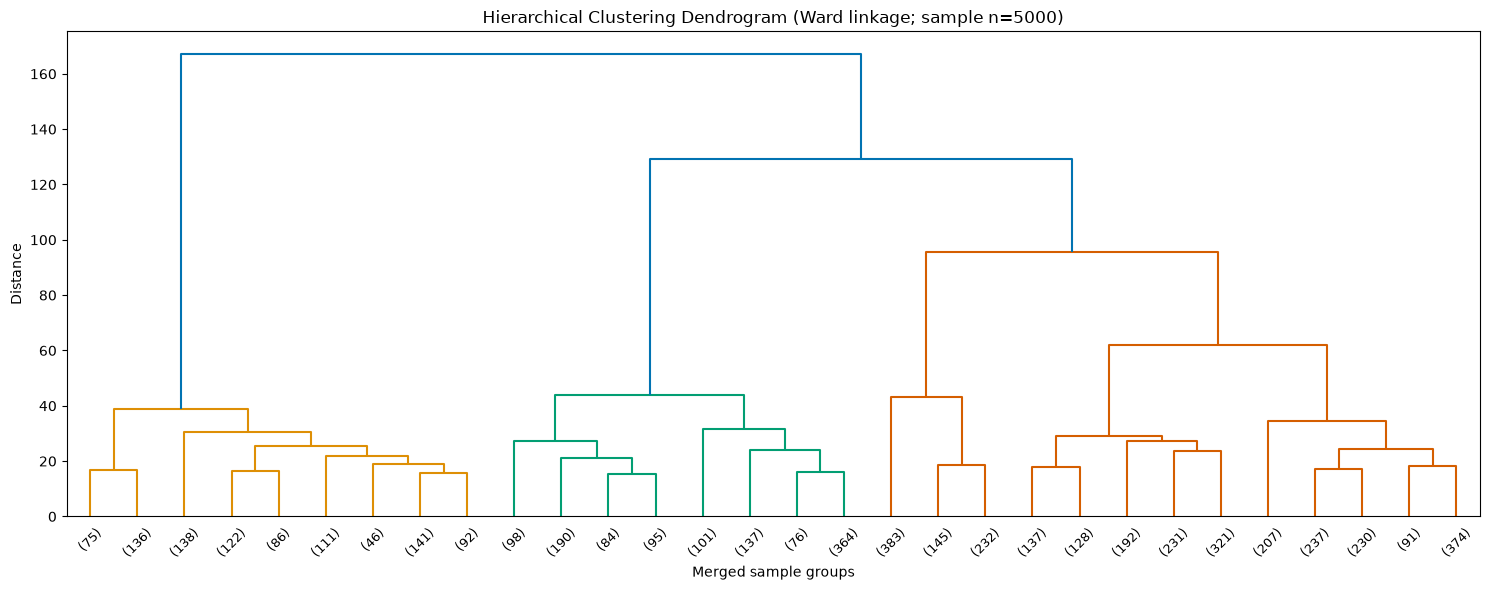

In [22]:
# Keep the same 5,000-row sample for the dendrogram and later comparisons.
DENDROGRAM_SAMPLE_SIZE = min(5_000, len(X_hier))
dendro_local_positions = np.sort(
    np.random.RandomState(RANDOM_STATE).choice(
        len(X_hier), size=DENDROGRAM_SAMPLE_SIZE, replace=False
    )
)
X_dendro = X_hier[dendro_local_positions]

Z = linkage(X_dendro, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=9)
plt.title(f"Hierarchical Clustering Dendrogram (Ward linkage; sample n={len(X_dendro)})")
plt.xlabel("Merged sample groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


## 8. Fit final Agglomerative model and compare required metrics

K-Means is fitted on all 36,726 cleaned observations. Its existing labels are compared with Agglomerative labels on the same sample of up to 5,000 rows. Full-dataset K-Means metrics are reported in Section 12.


In [23]:
print("Agglomerative linkage used:", AGG_LINKAGE)

X_eval = X_hier
# Reuse labels from the K-Means model fitted on all cleaned observations.
kmeans_eval_labels = kmeans_labels[sample_positions]
# Fit Agglomerative only on the 5,000-row hierarchical sample.
agg_final = AgglomerativeClustering(n_clusters=KMEANS_K, linkage=AGG_LINKAGE)
agg_labels = agg_final.fit_predict(X_eval)

evaluation_rows = []
for model_name, labels in [("K-Means (fit on all rows)", kmeans_eval_labels), (f"Agglomerative ({AGG_LINKAGE})", agg_labels)]:
    evaluation_rows.append({
        "Algorithm": model_name,
        "Rows evaluated": len(X_eval),
        "Number of clusters": len(np.unique(labels)),
        "Smallest cluster": int(np.bincount(labels).min()),
        "Silhouette Score": silhouette_score(X_eval, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_eval, labels)
    })
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))


Agglomerative linkage used: complete


,Algorithm,Rows evaluated,Number of clusters,Smallest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (fit on all rows),5000,3,1131,0.3162,1.2135,2868.1656
1,Agglomerative (complete),5000,3,1023,0.2890,1.1981,2462.2565


## 9. PCA visualisation — both algorithms
PCA reduces the scaled feature matrix to two dimensions for visualisation. The clustering models are fitted on the original scaled features, not on these two plotted components.

In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_eval)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained by 2 components:",
      round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio: [0.5422 0.1974]
Total variance explained by 2 components: 0.7396


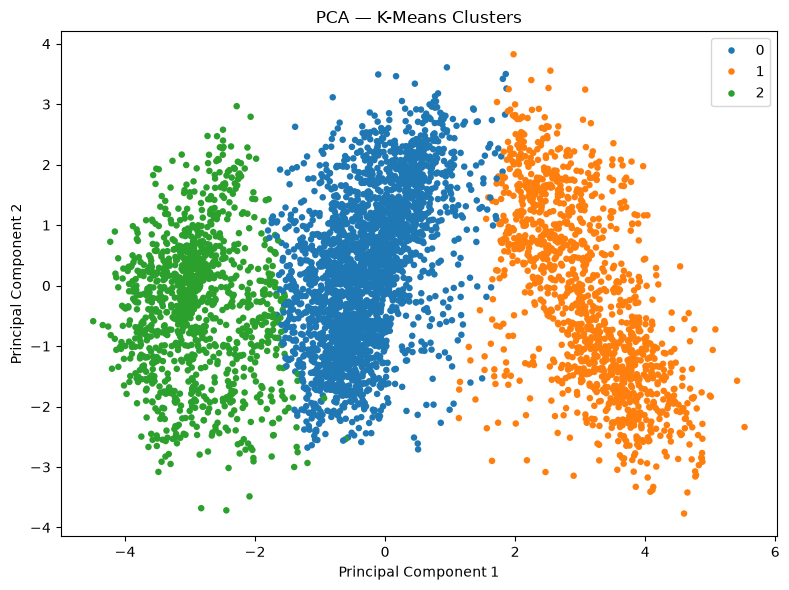

In [25]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_eval_labels,
                palette="tab10", s=22, linewidth=0, legend="brief")
plt.title("PCA — K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

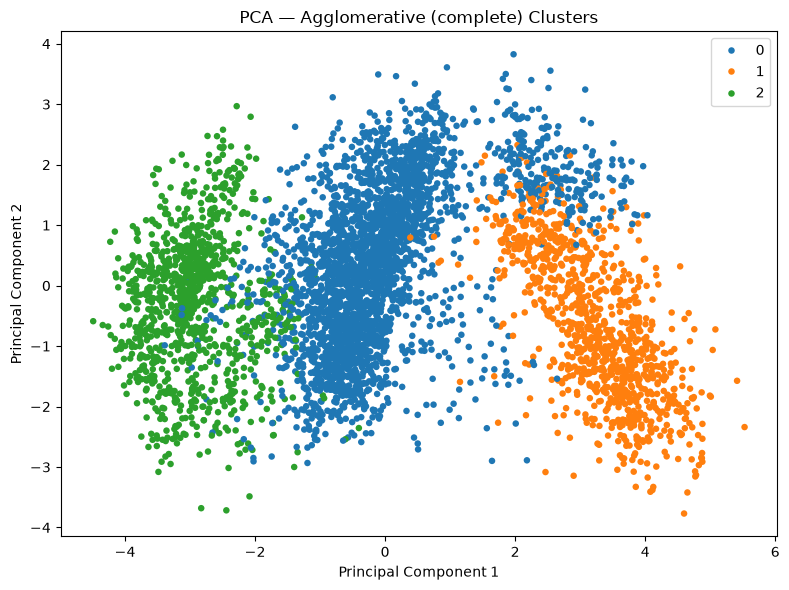

In [26]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels,
                palette="tab10", s=22, linewidth=0, legend="brief")
plt.title(f"PCA — Agglomerative ({AGG_LINKAGE}) Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

## 10. t-SNE visualisation

t-SNE is computationally intensive and is used here on a fixed sample. It is a visualisation of local structure, not a clustering algorithm or a substitute for the three required metrics.

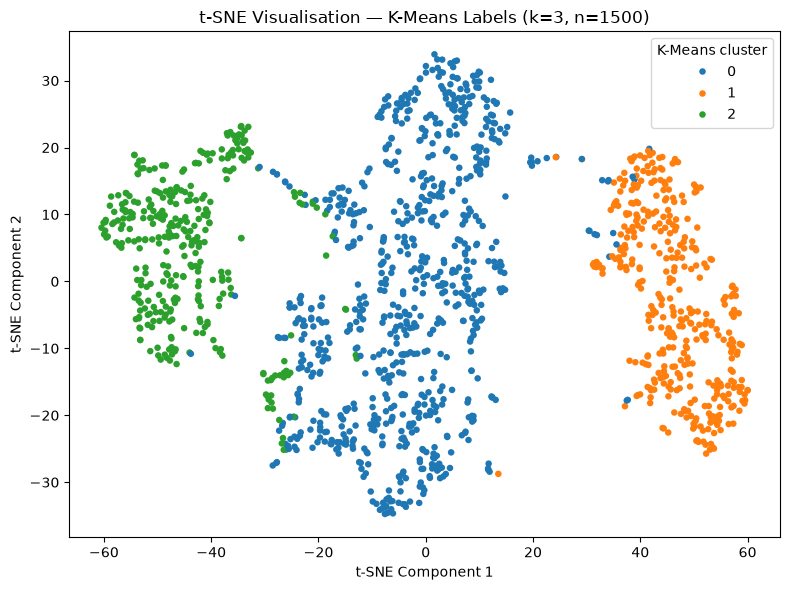

In [27]:
TSNE_SAMPLE_SIZE = min(1500, len(df))
tsne_positions = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(df), size=TSNE_SAMPLE_SIZE, replace=False))
X_tsne_input = X_scaled[tsne_positions]
tsne_labels = kmeans_labels[tsne_positions]

tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=min(30, (TSNE_SAMPLE_SIZE - 1) / 3),
            init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=tsne_labels,
                palette="tab10", s=22, linewidth=0)
plt.title(f"t-SNE Visualisation — K-Means Labels (k={KMEANS_K}, n={TSNE_SAMPLE_SIZE})")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="K-Means cluster")
plt.tight_layout()
plt.show()

## 11. Interpret clusters using CO and NOx after clustering

The emissions were excluded from the clustering inputs. Compare their distributions across K-Means clusters to help interpret the operating groups; observed associations do not establish causation.

In [28]:
cluster_profile = df.groupby("KMeans_Cluster")[operating_features + emission_features].mean()
cluster_sizes = df["KMeans_Cluster"].value_counts().sort_index().rename("Number of rows")
cluster_profile = cluster_profile.join(cluster_sizes)
print("Mean of each feature per cluster (original units):")
display(cluster_profile.round(3))

# CO is skewed (a few very large values), so medians are shown as well as means
print("Median CO and NOX per cluster:")
display(df.groupby("KMeans_Cluster")[emission_features].median().round(3))

Mean of each feature per cluster (original units):


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Number of rows
KMeans_Cluster,,,,,,,,,,,,
0,18.440,1012.719,77.705,3.898,25.107,1085.060,549.839,132.987,11.975,1.761,65.401,18904
1,17.556,1013.876,74.195,4.685,31.522,1099.602,539.431,154.692,13.600,1.281,62.273,9131
2,16.289,1012.976,82.111,3.172,20.295,1054.660,548.525,112.370,10.629,4.849,68.243,8691


Median CO and NOX per cluster:


,CO,NOX
KMeans_Cluster,,
0,1.609,64.384
1,1.182,61.468
2,4.273,64.245


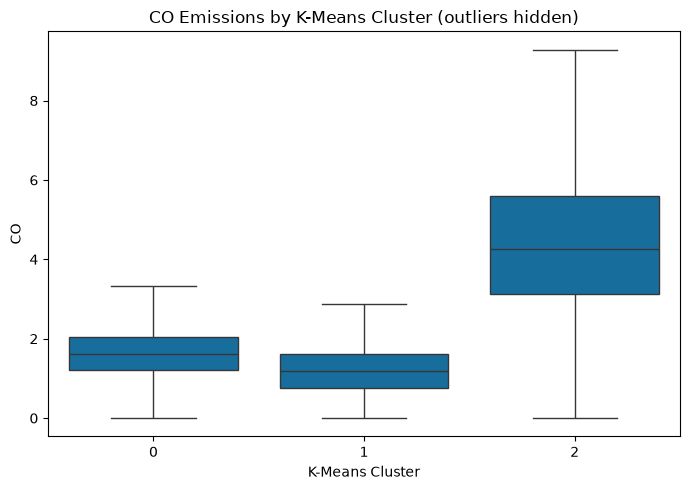

In [29]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="KMeans_Cluster", y="CO", showfliers=False)
plt.title("CO Emissions by K-Means Cluster (outliers hidden)")
plt.xlabel("K-Means Cluster")
plt.ylabel("CO")
plt.tight_layout()
plt.show()

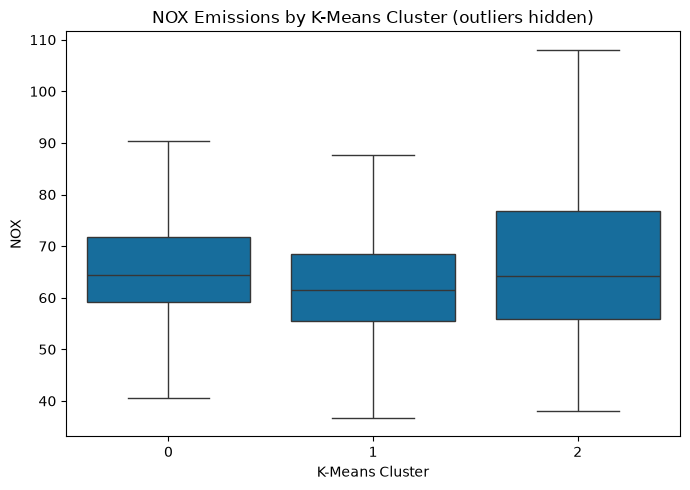

In [30]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="KMeans_Cluster", y="NOX", showfliers=False)
plt.title("NOX Emissions by K-Means Cluster (outliers hidden)")
plt.xlabel("K-Means Cluster")
plt.ylabel("NOX")
plt.tight_layout()
plt.show()

### Emission scatterplots by K-Means cluster

These plots relate CO and NOX to turbine energy yield, ambient temperature and turbine inlet temperature. Points are colored by the full-data K-Means cluster and use the same reproducible subset for readability.


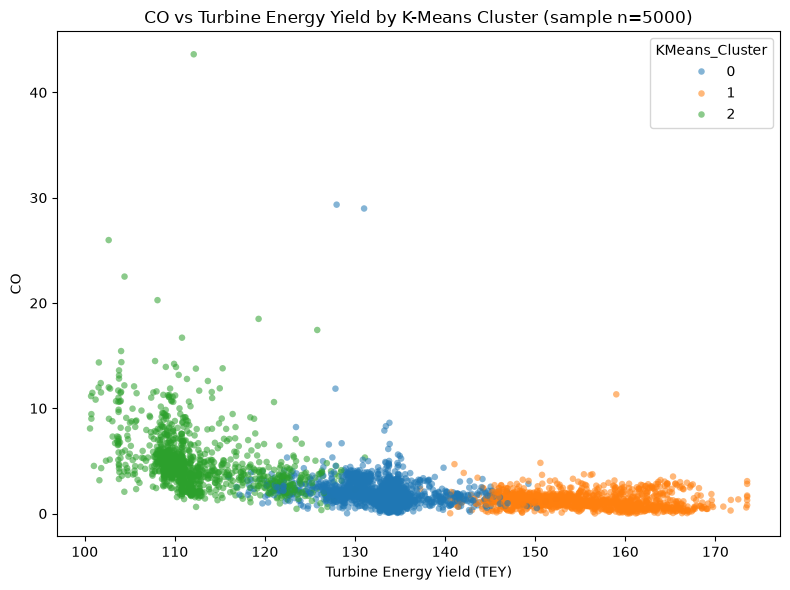

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.iloc[scatter_positions], x="TEY", y="CO", hue="KMeans_Cluster",
                palette="tab10", alpha=0.55, s=22, linewidth=0)
plt.title(f"CO vs Turbine Energy Yield by K-Means Cluster (sample n={SCATTER_SAMPLE_SIZE})")
plt.xlabel("Turbine Energy Yield (TEY)")
plt.ylabel("CO")
plt.tight_layout()
plt.show()

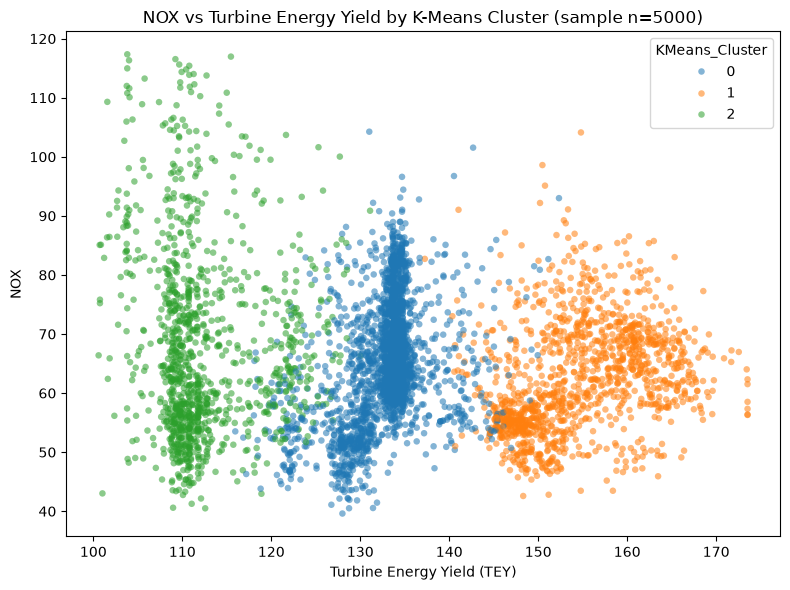

In [32]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.iloc[scatter_positions], x="TEY", y="NOX", hue="KMeans_Cluster",
                palette="tab10", alpha=0.55, s=22, linewidth=0)
plt.title(f"NOX vs Turbine Energy Yield by K-Means Cluster (sample n={SCATTER_SAMPLE_SIZE})")
plt.xlabel("Turbine Energy Yield (TEY)")
plt.ylabel("NOX")
plt.tight_layout()
plt.show()

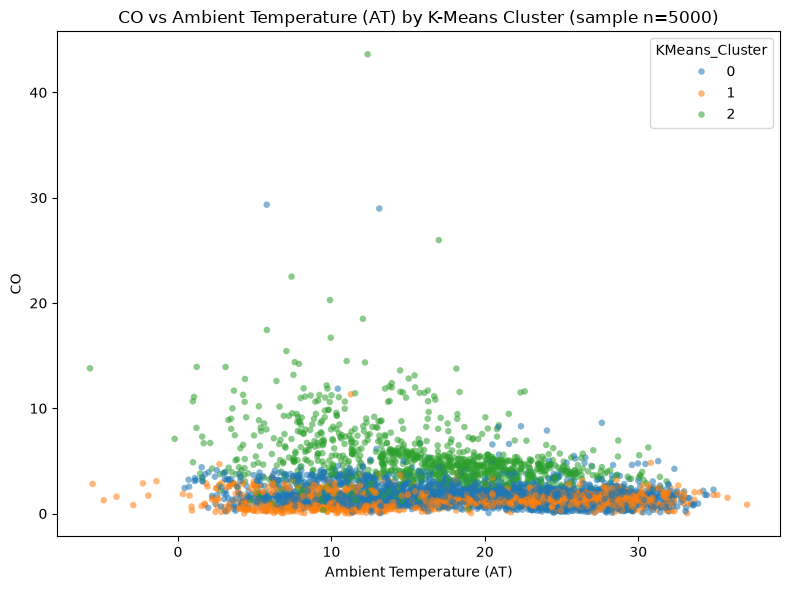

In [33]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.iloc[scatter_positions], x="AT", y="CO", hue="KMeans_Cluster",
                palette="tab10", alpha=0.55, s=22, linewidth=0)
plt.title(f"CO vs Ambient Temperature (AT) by K-Means Cluster (sample n={SCATTER_SAMPLE_SIZE})")
plt.xlabel("Ambient Temperature (AT)")
plt.ylabel("CO")
plt.tight_layout()
plt.show()

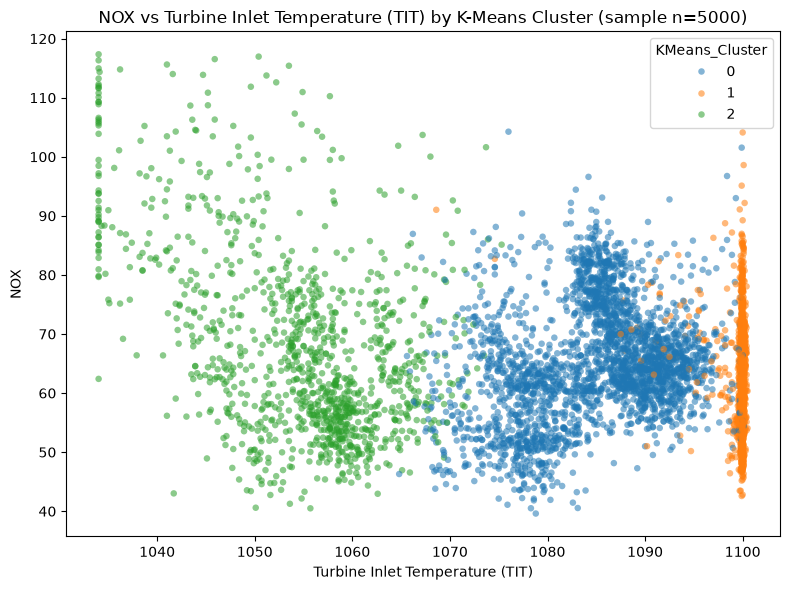

In [34]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.iloc[scatter_positions], x="TIT", y="NOX", hue="KMeans_Cluster",
                palette="tab10", alpha=0.55, s=22, linewidth=0)
plt.title(f"NOX vs Turbine Inlet Temperature (TIT) by K-Means Cluster (sample n={SCATTER_SAMPLE_SIZE})")
plt.xlabel("Turbine Inlet Temperature (TIT)")
plt.ylabel("NOX")
plt.tight_layout()
plt.show()

## 12. Final results summary, rubric check and conclusion

The final algorithm comparison evaluates K-Means and the selected Agglomerative linkage on all cleaned observations. The four-linkage comparison and K-Means metrics also use the full dataset; only the dendrogram and t-SNE visualisations use smaller samples.


In [35]:
print(f"FINAL ALGORITHM COMPARISON — SAME {len(X_eval):,}-ROW SAMPLE")
display(evaluation_df.round(4))

print(f"LINKAGE STRATEGY COMPARISON — SAME {len(X_hier):,}-ROW SAMPLE")
display(linkage_results_df.round(4))

# Reuse the full-data Silhouette result already calculated for the selected k.
full_km_metrics = {
    "Algorithm": f"K-Means (k={KMEANS_K}) — full cleaned dataset",
    "Rows fitted": len(df),
    "Silhouette Score (all rows)": float(k_table.loc[k_table["k"] == KMEANS_K, "Silhouette (all rows)"].iloc[0]),
    "Davies-Bouldin Index (all rows)": davies_bouldin_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Index (all rows)": calinski_harabasz_score(X_scaled, kmeans_labels),
}
print("K-MEANS METRICS — FITTED ON ALL CLEANED OBSERVATIONS")
display(pd.DataFrame([full_km_metrics]).round(4))

print("K-Means cluster sizes (full cleaned dataset)")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("instances"))

FINAL ALGORITHM COMPARISON — SAME 5,000-ROW SAMPLE


,Algorithm,Rows evaluated,Number of clusters,Smallest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (fit on all rows),5000,3,1131,0.3162,1.2135,2868.1656
1,Agglomerative (complete),5000,3,1023,0.2890,1.1981,2462.2565


LINKAGE STRATEGY COMPARISON — SAME 5,000-ROW SAMPLE


,Linkage,Smallest cluster,Largest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Valid (no tiny cluster)
0,average,2,3678,0.3242,0.9286,1544.8512,False
1,complete,1023,2906,0.2890,1.1981,2462.2565,True
2,ward,947,2908,0.2878,1.1905,2454.8464,True
3,single,1,4998,0.0904,0.7218,2.7109,False


K-MEANS METRICS — FITTED ON ALL CLEANED OBSERVATIONS


,Algorithm,Rows fitted,Silhouette Score (all rows),Davies-Bouldin Index (all rows),Calinski-Harabasz Index (all rows)
0,K-Means (k=3) — full cleaned dataset,36726,0.3184,1.2105,21306.8276


K-Means cluster sizes (full cleaned dataset)


,instances
KMeans_Cluster,
0,18904
1,9131
2,8691


In [36]:
km_row = evaluation_df.iloc[0]
ag_row = evaluation_df.iloc[1]
def status(ok):
    return "Included" if ok else "Needs attention"

rubric_matrix = pd.DataFrame([
    ["B1", "K-Means fitted and labels obtained", f"k={KMEANS_K}; {len(kmeans_labels):,} labels on all cleaned rows", status(len(kmeans_labels) == len(df))],
    ["B1", "Agglomerative fitted and labels obtained", f"{AGG_LINKAGE}; k={KMEANS_K}; {len(agg_labels):,} labels on the 5,000-row sample", status(len(agg_labels) == len(X_eval))],
    ["B2", "All three metrics for both algorithms", "Same-sample comparison table in Section 8", status(all(c in evaluation_df.columns for c in ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index"]))],
    ["B2", "K-Means elbow curve", "Section 6", "Included"],
    ["B2", "Four-linkage comparison, CO/NOX profiles and dendrogram", "Section 7", "Included"],
    ["B3", "PCA 2-D cluster plots for both algorithms", "Section 9", "Included"],
    ["B3", "t-SNE visualisation for at least one algorithm", "Section 10", "Included"],
    ["Method", "CO/NOX/Year excluded from clustering inputs", "Nine operating features only", status(not (set(operating_features) & set(emission_features + ["Year"])))],
], columns=["Rubric", "Requirement", "Evidence", "Status"])
print("CLUSTERING RUBRIC CHECK")
display(rubric_matrix)

CLUSTERING RUBRIC CHECK


,Rubric,Requirement,Evidence,Status
0,B1,K-Means fitted and labels obtained,"k=3; 36,726 labels on all cleaned rows",Included
1,B1,Agglomerative fitted and labels obtained,"complete; k=3; 5,000 labels on the 5,000-row s...",Included
2,B2,All three metrics for both algorithms,Same-sample comparison table in Section 8,Included
3,B2,K-Means elbow curve,Section 6,Included
4,B2,"Four-linkage comparison, CO/NOX profiles and d...",Section 7,Included
5,B3,PCA 2-D cluster plots for both algorithms,Section 9,Included
6,B3,t-SNE visualisation for at least one algorithm,Section 10,Included
7,Method,CO/NOX/Year excluded from clustering inputs,Nine operating features only,Included


In [37]:
def describe_silhouette(s):
    if s > 0.70: return "strong separation in this representation"
    if s > 0.50: return "reasonably separated groups in this representation"
    if s > 0.25: return "some cluster structure, with potential overlap"
    return "limited separation in this representation"

by_load = df.groupby("KMeans_Cluster")["TEY"].mean().sort_values()
med = df.groupby("KMeans_Cluster")[emission_features].median()
low, high = by_load.index[0], by_load.index[-1]

better = sum([
    km_row["Silhouette Score"] > ag_row["Silhouette Score"],
    km_row["Davies-Bouldin Index"] < ag_row["Davies-Bouldin Index"],
    km_row["Calinski-Harabasz Index"] > ag_row["Calinski-Harabasz Index"],
])

print("CONCLUSION SUMMARY (based on the outputs above)\n")
print(f"1) K-Means uses all {len(df):,} cleaned observations and all nine operating-condition features; selected k = {KMEANS_K}.")
print(f"2) On the same {len(X_eval):,}-row evaluation sample:")
print(f"   K-Means: Silhouette {km_row['Silhouette Score']:.4f} | Davies-Bouldin {km_row['Davies-Bouldin Index']:.4f} | Calinski-Harabasz {km_row['Calinski-Harabasz Index']:,.2f}")
print(f"   Agglomerative ({AGG_LINKAGE}): Silhouette {ag_row['Silhouette Score']:.4f} | Davies-Bouldin {ag_row['Davies-Bouldin Index']:.4f} | Calinski-Harabasz {ag_row['Calinski-Harabasz Index']:,.2f}")
print(f"   K-Means is better on {better} of the three metrics in this sample; interpret the metrics together with cluster sizes and profiles.")
print(f"3) Silhouette interpretation: {describe_silhouette(km_row['Silhouette Score'])}.")
print(f"4) PCA's first two components explain {pca.explained_variance_ratio_.sum():.1%} of the variance; the 2-D plot is a simplified view.")
print(f"5) Cluster {low} has the lowest mean turbine energy yield ({by_load[low]:.2f}); cluster {high} has the highest ({by_load[high]:.2f}).")
print(f"   Median CO: cluster {low}={med.loc[low, 'CO']:.3f}, cluster {high}={med.loc[high, 'CO']:.3f}; median NOX: cluster {low}={med.loc[low, 'NOX']:.3f}, cluster {high}={med.loc[high, 'NOX']:.3f}.")
print("6) Limitations: hierarchical clustering, dendrogram and t-SNE use documented samples; these clusters describe similarity, not causation.")

CONCLUSION SUMMARY (based on the outputs above)

1) K-Means uses all 36,726 cleaned observations and all nine operating-condition features; selected k = 3.
2) On the same 5,000-row evaluation sample:
   K-Means: Silhouette 0.3162 | Davies-Bouldin 1.2135 | Calinski-Harabasz 2,868.17
   Agglomerative (complete): Silhouette 0.2890 | Davies-Bouldin 1.1981 | Calinski-Harabasz 2,462.26
   K-Means is better on 2 of the three metrics in this sample; interpret the metrics together with cluster sizes and profiles.
3) Silhouette interpretation: some cluster structure, with potential overlap.
4) PCA's first two components explain 74.0% of the variance; the 2-D plot is a simplified view.
5) Cluster 2 has the lowest mean turbine energy yield (112.37); cluster 1 has the highest (154.69).
   Median CO: cluster 2=4.273, cluster 1=1.182; median NOX: cluster 2=64.245, cluster 1=61.468.
6) Limitations: hierarchical clustering, dendrogram and t-SNE use documented samples; these clusters describe similarity

### Notes for the write-up

- State the actual cleaned row count and all nine input features.
- Explain that CO and NOx were reserved for post-clustering interpretation, including the four-linkage comparison.
- State clearly that K-Means and the four Agglomerative linkage comparisons use all cleaned observations; the dendrogram uses a smaller sample for readability.
- Report metric values exactly as produced by the executed notebook. Do not claim a target score was achieved unless the displayed output supports it.
- Discuss limitations: distance-based results depend on scaling and feature representation; cluster associations with emissions are not causal.

## 13. Export the selected clustering models for the GUI

The K-Means bundle is fitted on every cleaned observation and is used by the interactive app. The selected Agglomerative model is saved too for reproducibility; it is fitted on all cleaned observations and does not provide a `predict` method for new observations.


In [38]:
from pathlib import Path
import joblib

# Support running this notebook from either the repository root or notebooks/.
working_dir = Path.cwd()
if working_dir.name == "notebooks":
    project_root = working_dir.parent
elif (working_dir / "notebooks").is_dir():
    project_root = working_dir
else:
    project_root = Path(__file__).resolve().parents[1] if "__file__" in globals() else working_dir.parent
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# These summaries describe each full-data K-Means cluster in the original feature units.
cluster_counts_for_app = {
    int(cluster): int(count)
    for cluster, count in df["KMeans_Cluster"].value_counts().sort_index().items()
}
cluster_means_for_app = {
    int(cluster): values.to_dict()
    for cluster, values in df.groupby("KMeans_Cluster")[operating_features].mean().iterrows()
}
emission_medians_for_app = {
    int(cluster): values.to_dict()
    for cluster, values in df.groupby("KMeans_Cluster")[emission_features].median().iterrows()
}

kmeans_bundle = {
    "model": kmeans,
    "model_name": f"K-Means (k={KMEANS_K})",
    "scaler": scaler,
    "feature_columns": operating_features,
    "n_clusters": int(KMEANS_K),
    "training_rows": int(len(X)),
    "cluster_counts": cluster_counts_for_app,
    "cluster_means": cluster_means_for_app,
    "emission_medians": emission_medians_for_app,
    "metrics": full_km_metrics,
    "random_state": int(RANDOM_STATE),
}
kmeans_path = models_dir / "gas_turbine_clustering_model.pkl"
joblib.dump(kmeans_bundle, kmeans_path)

# Save the selected Agglomerative estimator and the metrics from its fixed evaluation sample.
agg_metrics = evaluation_df.loc[
    evaluation_df["Algorithm"] == f"Agglomerative ({AGG_LINKAGE})"
].iloc[0].to_dict()
agglomerative_bundle = {
    "model": agg_final,
    "model_name": f"Agglomerative (linkage={AGG_LINKAGE}, k={KMEANS_K})",
    "scaler": scaler,
    "feature_columns": operating_features,
    "n_clusters": int(KMEANS_K),
    "linkage": str(AGG_LINKAGE),
    "training_rows": int(len(X_eval)),
    "metrics": agg_metrics,
    "random_state": int(RANDOM_STATE),
    "supports_new_observation_prediction": False,
}
agglomerative_path = models_dir / "gas_turbine_agglomerative_model.pkl"
joblib.dump(agglomerative_bundle, agglomerative_path)

print(f"Saved app-ready K-Means bundle: {kmeans_path}")
print(f"Saved selected Agglomerative bundle: {agglomerative_path}")


Saved app-ready K-Means bundle: c:\Users\Sridev\Downloads\models\gas_turbine_clustering_model.pkl
Saved selected Agglomerative bundle: c:\Users\Sridev\Downloads\models\gas_turbine_agglomerative_model.pkl
